<a href="https://colab.research.google.com/github/youngbean0519/Self-Project/blob/main/notebooks/07_bilstm.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### 1. Colab environment and project paths

In [ ]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [ ]:
!git clone https://github.com/youngbean0519/Self-Project.git

Cloning into 'Self-Project'...
remote: Enumerating objects: 88, done.
remote: Counting objects: 100% (88/88), done.
remote: Compressing objects: 100% (70/70), done.
remote: Total 88 (delta 31), reused 60 (delta 10), pack-reused 0 (from 0)
Receiving objects: 100% (88/88), 572.75 KiB | 26.03 MiB/s, done.
Resolving deltas: 100% (31/31), done.


In [ ]:
import os
import sys

PROJECT_DIR = "/content/Self-Project"
SRC_DIR = os.path.join(PROJECT_DIR, "src")
RESULTS_DIR = os.path.join(PROJECT_DIR, "results")

DATA_DIR = "/content/drive/MyDrive/26_KOTE/data"
ARTIFACT_DIR = "/content/drive/MyDrive/26_KOTE/artifacts/week7_bilstm"

os.makedirs(ARTIFACT_DIR, exist_ok=True)

if PROJECT_DIR not in sys.path:
    sys.path.append(PROJECT_DIR)

if SRC_DIR not in sys.path:
    sys.path.append(SRC_DIR)

print("PROJECT_DIR:", PROJECT_DIR)
print("DATA_DIR:", DATA_DIR)
print("ARTIFACT_DIR:", ARTIFACT_DIR)
WEEK6_ARTIFACT_DIR = "/content/drive/MyDrive/26_KOTE/artifacts/week6_textcnn"

PROJECT_DIR: /content/Self-Project
DATA_DIR: /content/drive/MyDrive/26_KOTE/data
ARTIFACT_DIR: /content/drive/MyDrive/26_KOTE/artifacts/week7_bilstm


In [ ]:
!pip install -q sentencepiece

In [ ]:
import random
import time
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torch.nn.utils.rnn import pack_padded_sequence
from sklearn.metrics import (
    f1_score,
    precision_score,
    recall_score,
    hamming_loss,
    average_precision_score
)
import sentencepiece as spm
import preprocessing.text as text_preprocessing
import utils.labels as utils_labels

In [ ]:
TRAIN_PATH = os.path.join(DATA_DIR, "train.tsv")
VAL_PATH = os.path.join(DATA_DIR, "val.tsv")
TEST_PATH = os.path.join(DATA_DIR, "test.tsv")

print(TRAIN_PATH)
print(VAL_PATH)
print(TEST_PATH)

/content/drive/MyDrive/26_KOTE/data/train.tsv
/content/drive/MyDrive/26_KOTE/data/val.tsv
/content/drive/MyDrive/26_KOTE/data/test.tsv


In [ ]:
train_df = pd.read_csv(TRAIN_PATH, sep="\t", header=None, names=["id", "text", "labels"])
val_df = pd.read_csv(VAL_PATH, sep="\t", header=None, names=["id", "text", "labels"])
test_df = pd.read_csv(TEST_PATH, sep="\t", header=None, names=["id", "text", "labels"])

print("Train:", train_df.shape)
print("Validation:", val_df.shape)
print("Test:", test_df.shape)

print(train_df.columns)
train_df.head()

Train: (40000, 3)
Validation: (5000, 3)
Test: (5000, 3)
Index(['id', 'text', 'labels'], dtype='object')


,id,text,labels
0,39087,내가 톰행크스를 좋아하긴 했나보다... 초기 영화 빼고는 다 봤네.,"2,13,15,16,29,39"
1,30893,"정말 상상을 초월하는 무개념 진상들 상대하다 우울증, 공항장애 걸리는 공무원 많아요...","0,5,7,10,19,22,29,35,36,38"
2,45278,"새로운 세상과 조우한 자의 어린아이 같은 반응, 어쩌면 회복된 것은 눈이 아닌 순수...","1,2,7"
3,16398,미역은 원생생물계 산호초는 동물ㅇㅇ 아 미역이 바다의 새ㄱㅇㄱㅋㅋㅋㅋㅋㅋㅋㅋㅋㅋ,"9,15,20,23,26,28,29"
4,13653,네 맞습니다 플스는 역시 30프레임이 어울리죠 ㅎ,"1,2,8,9,11,13,15,16,28,29,32,40,42"


In [ ]:
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
  torch.cuda.manual_seed_all(SEED)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)

if torch.cuda.is_available():
  print("GPU:", torch.cuda.get_device_name(0))

Device: cuda
GPU: NVIDIA L4


### 2. Same preprocessing and labels as Week 06

In [ ]:
def make_preprocessed_texts(df, normalize_repeat, remove_symbols):
  return df["text"].astype(str).apply(
      lambda text: text_preprocessing.preprocess_text(
          text,
          normalize_repeat=normalize_repeat,
          remove_symbols=remove_symbols
      )
  )

In [ ]:
train_texts = make_preprocessed_texts(
    train_df,
    normalize_repeat=True,
    remove_symbols=False
)

val_texts = make_preprocessed_texts(
    val_df,
    normalize_repeat=True,
    remove_symbols=False
)

test_texts = make_preprocessed_texts(
    test_df,
    normalize_repeat=True,
    remove_symbols=False
)

print("Train:", len(train_texts))
print("Validation:", len(val_texts))
print("Test:", len(test_texts))

Train: 40000
Validation: 5000
Test: 5000


In [ ]:
NUM_LABELS = 44

def make_multihot_labels(df, num_labels=44):
  targets = np.zeros((len(df), num_labels), dtype=np.float32)

  for i, label_string in enumerate(df["labels"].astype(str)):
    label_indices = [
        int(x.strip())
        for x in label_string.split(",")
        if x.strip()
    ]

    targets[i, label_indices] = 1.0

  return targets

y_train = make_multihot_labels(train_df)
y_val = make_multihot_labels(val_df)
y_test = make_multihot_labels(test_df)

print("Train:", y_train.shape)
print("Validation:", y_val.shape)
print("Test:", y_test.shape)

Train: (40000, 44)
Validation: (5000, 44)
Test: (5000, 44)


### 3. Load the existing SentencePiece tokenizer

In [ ]:
SP_MODEL_PATH = os.path.join(WEEK6_ARTIFACT_DIR, "sentencepiece", "kote_sp.model")
if not os.path.isfile(SP_MODEL_PATH):
  raise FileNotFoundError(
      f"Missing Week 06 tokenizer: {SP_MODEL_PATH}\n"
      "Run Week 06 first of copy its saved sentencepiece folder to this location."
  )
tokenizer = spm.SentencePieceProcessor()
assert tokenizer.load(SP_MODEL_PATH)
PAD_IDX, UNK_IDX = tokenizer.pad_id(), tokenizer .unk_id()
assert PAD_IDX == 0 and UNK_IDX == 1
assert tokenizer.get_piece_size() == 8000
print("Loaded tokenizer:", SP_MODEL_PATH)
print("Vocabulary:", tokenizer.get_piece_size(), "PAD:", PAD_IDX, "UNK:", UNK_IDX)

Loaded tokenizer: /content/drive/MyDrive/26_KOTE/artifacts/week6_textcnn/sentencepiece/kote_sp.model
Vocabulary: 8000 PAD: 0 UNK: 1


In [ ]:
train_lengths = train_texts.apply(lambda s: len(tokenizer.encode(str(s), out_type=int)))
p99 = int(np.percentile(train_lengths, 99))
computed_max_len = int(np.ceil(p99 / 8) * 8)
MAX_LEN = 120
print("99th percentile:", p99, "Week 06 rule gives:", computed_max_len)
print("Using shared MAX_LEN:", MAX_LEN)
print("Train truncation rate:", float((train_lengths > MAX_LEN).mean()))
if computed_max_len != MAX_LEN:
    print("NOTE: token length percentile differs from Week 06; check data/preprocessing versions.")

99th percentile: 116 Week 06 rule gives: 120
Using shared MAX_LEN: 120
Train truncation rate: 0.00845


### 4. Dataset and DataLoader

In [ ]:
class KOTEDataset(Dataset):
  def __init__(self, texts, labels, tokenizer, max_len):
    self.texts = texts.reset_index(drop=True)
    self.labels = labels
    self.tokenizer = tokenizer
    self.max_len = max_len

  def __len__(self):
    return len(self.texts)

  def __getitem__(self, idx):
    ids = self.tokenizer.encode(str(self.texts.iloc[idx]), out_type=int)[:self.max_len]
    # pack_padded_sequence requires length >= 1 even for empty input.
    length = max(1, len(ids))
    ids = ids + [PAD_IDX] * (self.max_len - len(ids))
    return {
        "input_ids": torch.tensor(ids, dtype=torch.long),
        "length": torch.tensor(length, dtype=torch.long),
        "labels": torch.tensor(self.labels[idx], dtype=torch.float32)
    }

train_dataset = KOTEDataset(train_texts, y_train, tokenizer, MAX_LEN)
val_dataset = KOTEDataset(val_texts, y_val, tokenizer, MAX_LEN)
test_dataset = KOTEDataset(test_texts, y_test, tokenizer, MAX_LEN)
BATCH_SIZE = 128
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)
batch = next(iter(train_loader))
print({key: tuple(value.shape) for key, value in batch.items()})

{'input_ids': (128, 120), 'length': (128,), 'labels': (128, 44)}


### 5. BiLSTM architecture

In [ ]:
class BiLSTM(nn.Module):
  def __init__(self, vocab_size, embed_dim, hidden_dim, num_layers, num_labels, dropout, padding_idx):
    super().__init__()
    self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=padding_idx)
    self.lstm = nn.LSTM(
        input_size=embed_dim,
        hidden_size=hidden_dim,
        num_layers=num_layers,
        batch_first=True,
        bidirectional=True,
        dropout=dropout if num_layers > 1 else 0.0
    )
    self.dropout = nn.Dropout(dropout)
    self.classifier = nn.Linear(hidden_dim * 2, num_labels)

  def forward(self, input_ids, lengths):
    embedded = self.embedding(input_ids)
    packed = pack_padded_sequence(embedded, lengths.cpu(), batch_first=True, enforce_sorted=False)
    _, (hidden, _) = self.lstm(packed)
    features = torch.cat((hidden[-2], hidden[-1]), dim=1)
    return self.classifier(self.dropout(features))

EMBED_DIM = 200               # Same as Week 06
HIDDEN_DIM = 128              # BiLSTM-specific
NUM_LAYERS = 1               # One bidirectional layer
DROPOUT = 0.3                # Same classifier dropout as Week 06
LEARNING_RATE = 1e-3         # Same initial LR as Week 06
model = BiLSTM(tokenizer.get_piece_size(), EMBED_DIM, HIDDEN_DIM,
               NUM_LAYERS, NUM_LABELS, DROPOUT, PAD_IDX).to(device)
criterion = nn.BCEWithLogitsLoss()
optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=1e-4)
print(model)
print("Trainable parameters:", sum(p.numel() for p in model.parameters() if p.requires_grad))

BiLSTM(
  (embedding): Embedding(8000, 200, padding_idx=0)
  (lstm): LSTM(200, 128, batch_first=True, bidirectional=True)
  (dropout): Dropout(p=0.3, inplace=False)
  (classifier): Linear(in_features=256, out_features=44, bias=True)
)
Trainable parameters: 1949228


### 6. Training and validation metrics

In [ ]:
def train_one_epoch(model, dataloader, criterion, optimizer, device):
    model.train()
    total_loss = 0.0
    for batch in dataloader:
        input_ids = batch["input_ids"].to(device)
        lengths = batch["length"]
        labels = batch["labels"].to(device)
        optimizer.zero_grad()
        logits = model(input_ids, lengths)
        loss = criterion(logits, labels)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()
        total_loss += loss.item()
    return total_loss / len(dataloader)

def predict(model, dataloader, device):
    model.eval()
    probabilities, labels = [], []
    with torch.no_grad():
        for batch in dataloader:
            logits = model(batch["input_ids"].to(device), batch["length"])
            probabilities.append(torch.sigmoid(logits).cpu().numpy())
            labels.append(batch["labels"].numpy())
    return np.vstack(probabilities), np.vstack(labels)

In [ ]:
def evaluate_multilabel(y_true, y_prob, threshold):
  y_pred = (y_prob >= threshold).astype(int)
  micro_f1 = f1_score(y_true, y_pred, average="micro", zero_division=0)
  macro_f1 = f1_score(y_true, y_pred, average="macro", zero_division=0)
  hamming = hamming_loss(y_true, y_pred)
  pr_auc_micro = average_precision_score(y_true, y_prob, average="micro")
  pr_auc_macro = average_precision_score(y_true, y_prob, average="macro")

  return {
      "threshold": threshold,
      "micro_f1": micro_f1,
      "macro_f1": macro_f1,
      "hamming": hamming,
      "pr_auc_micro": pr_auc_micro,
      "pr_auc_macro": pr_auc_macro
  }

In [ ]:
THRESHOLDS = np.arange(0.10, 0.61, 0.05)

def find_best_threshold(y_true, y_prob):
  results = []
  for threshold in THRESHOLDS:
    result = evaluate_multilabel(y_true, y_prob, threshold)
    results.append(result)

  results_df = pd.DataFrame(results)
  best_index = results_df["micro_f1"].idxmax()
  best_result = results_df.loc[best_index]

  return results_df, best_result

### 7. Train BiLSTM and save best checkpoint (validation Micro F1)

In [ ]:
MAX_EPOCHS = 15
PATIENCE = 3
BEST_MODEL_PATH = os.path.join(ARTIFACT_DIR, "bilstm_best.pt")
best_micro_f1, best_epoch, patience_counter = -1.0, 0, 0
history = []
start_time = time.time()
for epoch in range(1, MAX_EPOCHS + 1):
    train_loss = train_one_epoch(model, train_loader, criterion, optimizer, device)
    val_probs, val_labels = predict(model, val_loader, device)
    _, best_result = find_best_threshold(val_labels, val_probs)
    current_micro_f1 = float(best_result["micro_f1"])
    history.append({
        "epoch": epoch, "train_loss": train_loss,
        "threshold": float(best_result["threshold"]),
        "micro_f1": current_micro_f1,
        "macro_f1": float(best_result["macro_f1"]),
        "hamming_loss": float(best_result["hamming"]),
        "pr_auc_micro": float(best_result["pr_auc_micro"]),
        "pr_auc_macro": float(best_result["pr_auc_macro"])
    })
    print(
        f"Epoch {epoch:02d} | loss {train_loss:.4f} | threshold "
        f"{best_result['threshold']:.2f} | Micro F1 {current_micro_f1:.4f} | "
        f"Macro F1 {best_result['macro_f1']:.4f}"
    )
    if current_micro_f1 > best_micro_f1:
        best_micro_f1, best_epoch, patience_counter = current_micro_f1, epoch, 0
        torch.save(model.state_dict(), BEST_MODEL_PATH)
    else:
        patience_counter += 1
        if patience_counter >= PATIENCE:
            print("Early stopping.")
            break
training_time = time.time() - start_time
history_df = pd.DataFrame(history)
history_df.to_csv(os.path.join(ARTIFACT_DIR, "training_history.csv"), index=False)
print("Best epoch:", best_epoch, "Best Micro F1:", best_micro_f1, "Training time (s):", round(training_time, 2))

Epoch 01 | loss 0.4244 | threshold 0.25 | Micro F1 0.4916 | Macro F1 0.3025
Epoch 02 | loss 0.3706 | threshold 0.25 | Micro F1 0.5184 | Macro F1 0.3555
Epoch 03 | loss 0.3483 | threshold 0.25 | Micro F1 0.5318 | Macro F1 0.3917
Epoch 04 | loss 0.3323 | threshold 0.25 | Micro F1 0.5423 | Macro F1 0.4100
Epoch 05 | loss 0.3192 | threshold 0.30 | Micro F1 0.5445 | Macro F1 0.4044
Epoch 06 | loss 0.3077 | threshold 0.30 | Micro F1 0.5443 | Macro F1 0.4138
Epoch 07 | loss 0.2966 | threshold 0.30 | Micro F1 0.5461 | Macro F1 0.4129
Epoch 08 | loss 0.2867 | threshold 0.30 | Micro F1 0.5436 | Macro F1 0.4133
Epoch 09 | loss 0.2772 | threshold 0.30 | Micro F1 0.5431 | Macro F1 0.4185
Epoch 10 | loss 0.2691 | threshold 0.25 | Micro F1 0.5421 | Macro F1 0.4305
Early stopping.
Best epoch: 7 Best Micro F1: 0.5460650044420856 Training time (s): 92.45


### 8. Best checkpoint, validation threshold and plots

,threshold,micro_f1,macro_f1,hamming,pr_auc_micro,pr_auc_macro
0,0.10,0.485157,0.417692,0.320450,0.571893,0.423769
1,0.15,0.516799,0.431818,0.259977,0.571893,0.423769
2,0.20,0.534811,0.432919,0.221955,0.571893,0.423769
3,0.25,0.543945,0.426305,0.196495,0.571893,0.423769
4,0.30,0.546065,0.412879,0.178832,0.571893,0.423769
5,0.35,0.541340,0.394532,0.166950,0.571893,0.423769
6,0.40,0.532200,0.373260,0.158586,0.571893,0.423769
7,0.45,0.516900,0.348712,0.153191,0.571893,0.423769
8,0.50,0.496522,0.322242,0.150045,0.571893,0.423769
9,0.55,0.472811,0.295325,0.148114,0.571893,0.423769


Best validation metrics:


,BiLSTM
threshold,0.300000
micro_f1,0.546065
macro_f1,0.412879
hamming,0.178832
pr_auc_micro,0.571893
pr_auc_macro,0.423769


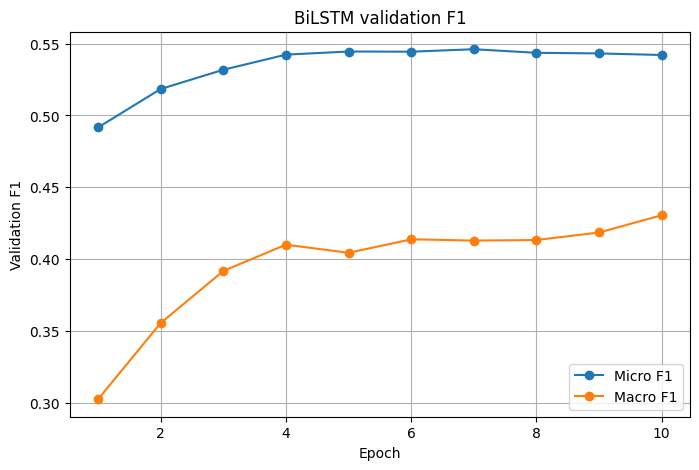

In [ ]:
model.load_state_dict(torch.load(BEST_MODEL_PATH, map_location=device, weights_only=True))
val_probs, val_labels = predict(model, val_loader, device)
threshold_results, best_val_result = find_best_threshold(val_labels, val_probs)
best_threshold = float(best_val_result["threshold"])
display(threshold_results)
print("Best validation metrics:")
display(best_val_result.to_frame(name="BiLSTM"))
threshold_results.to_csv(os.path.join(ARTIFACT_DIR, "threshold_results.csv"), index=False)
plt.figure(figsize=(8, 5))
plt.plot(history_df["epoch"], history_df["micro_f1"], marker="o", label="Micro F1")
plt.plot(history_df["epoch"], history_df["macro_f1"], marker="o", label="Macro F1")
plt.xlabel("Epoch"); plt.ylabel("Validation F1"); plt.title("BiLSTM validation F1")
plt.legend(); plt.grid(); plt.show()

### 9. Label-wise analysis and error patterns

In [ ]:
LABEL_NAMES = utils_labels.LABELS
assert len(LABEL_NAMES) == NUM_LABELS
val_pred = (val_probs >= best_threshold).astype(int)
labelwise_df = pd.DataFrame({
    "label_id": np.arange(NUM_LABELS),
    "label": LABEL_NAMES,
    "support": val_labels.sum(axis=0).astype(int),
    "predicted": val_pred.sum(axis=0),
    "precision": precision_score(val_labels, val_pred, average=None, zero_division=0),
    "recall": recall_score(val_labels, val_pred, average=None, zero_division=0),
    "f1": f1_score(val_labels, val_pred, average=None, zero_division=0)
})
labelwise_df.to_csv(os.path.join(ARTIFACT_DIR, "labelwise_validation.csv"), index=False, encoding="utf-8-sig")
display(labelwise_df.sort_values("f1").reset_index(drop=True))

,label_id,label,support,predicted,precision,recall,f1
0,18,공포/무서움,134,2,0.000000,0.000000,0.000000
1,17,부끄러움,286,7,0.142857,0.003497,0.006826
2,26,귀찮음,312,11,0.181818,0.006410,0.012384
3,25,패배/자기혐오,183,17,0.117647,0.010929,0.020000
4,30,죄책감,89,3,0.333333,0.011236,0.021739
5,35,부담/안_내킴,578,123,0.260163,0.055363,0.091298
6,36,서러움,234,82,0.256098,0.089744,0.132911
7,19,절망,455,201,0.308458,0.136264,0.189024
8,11,비장함,399,192,0.348958,0.167920,0.226734
9,27,힘듦/지침,477,264,0.344697,0.190776,0.245614


In [ ]:
# Representative validation errors: false negatives, false positives, and label-set mismatch
false_negatives = ((val_labels == 1) & (val_pred == 0)).sum(axis=1)
false_positives = ((val_labels == 0) & (val_pred == 1)).sum(axis=1)
error_df = pd.DataFrame({
    "text": val_df["text"].astype(str).to_numpy(),
    "true_labels": [np.where(row == 1)[0].tolist() for row in val_labels],
    "pred_labels": [np.where(row == 1)[0].tolist() for row in val_pred],
    "false_negative_count": false_negatives,
    "false_positive_count": false_positives,
    "total_label_errors": false_negatives + false_positives
})
error_df = error_df.sort_values("total_label_errors", ascending=False)
display(error_df.head(20))
error_df.to_csv(os.path.join(ARTIFACT_DIR, "validation_error_examples.csv"), index=False, encoding="utf-8-sig")

,text,true_labels,pred_labels,false_negative_count,false_positive_count,total_label_errors
2089,"나도 결혼5년차, 아직 아이없고, 처음부터 전업주부로 시작. 우리남편이 나 일스트레...","[1, 2, 4, 7, 9, 10, 13, 14, 15, 16, 26, 28, 32...","[0, 3, 6, 10, 12, 17, 20, 22, 23, 25, 27, 31, ...",15,15,30
3925,보면서 다시 느끼지만 진짜 그들만의 리그네요,"[0, 3, 5, 6, 10, 12, 19, 20, 21, 22, 23, 24, 2...","[1, 2, 7, 8, 15, 16, 29, 39, 42, 43]",19,9,28
742,전문대 레크레이션과 출신 재동이가 헌법을 논하고 90년대 후반 성인용품 팔고 음모론...,"[0, 3, 6, 10, 12, 20, 21, 22, 23, 31, 34, 41]","[1, 2, 7, 8, 13, 15, 16, 28, 32, 39, 40, 42]",12,12,24
4864,이번 세대는 m1에 램도 8gb라 게임용으로는 진짜 비빌급이 없겠네요. 아이패드 고...,"[1, 2, 4, 8, 9, 11, 13, 15, 24, 28, 32, 39, 42...","[0, 6, 10, 12, 20, 22, 23, 31, 33, 34]",14,10,24
4337,사나하고 결혼하면 싸울 일도 없을거 같은데,"[1, 2, 8, 14, 16, 28, 32, 40, 42, 43]","[0, 9, 10, 12, 20, 22, 23, 24, 29, 33, 35, 38,...",10,13,23
2367,잘 보고 갑니다 ~^^ 다시는 볼 일 없었음 좋겠어요. 언팔하고 갑니다,"[0, 6, 9, 10, 20, 22, 23, 31, 34, 35, 37]","[1, 2, 4, 7, 8, 13, 15, 16, 28, 40, 42, 43]",11,12,23
3694,저의 항문적 호기심을 폄하 하시는군요,"[0, 5, 6, 9, 12, 20, 21, 22, 23, 31, 33, 34]","[1, 2, 7, 8, 13, 15, 24, 28, 29, 39, 43]",12,11,23
3114,우리 사진 다 이런 식 2,"[0, 3, 10, 12, 17, 20, 22, 23, 24, 25, 33]","[1, 2, 8, 13, 14, 15, 16, 24, 28, 32, 39, 40, ...",10,13,23
4889,화사가 야한옷입으면 언니 너무예뻐요 경리 조현이 야한옷 입으면 성적대상화다 천박하...,"[0, 3, 6, 9, 10, 12, 20, 21, 22, 23, 24, 31]","[1, 2, 4, 8, 15, 28, 29, 39, 40, 42, 43]",12,11,23
2863,"이건 정말 배우들이 잘 연기 했을뿐, 8점의 평점대를 완전 무시해버리는 작품이네요.","[0, 6, 10, 12, 22, 23, 24, 33, 35, 37, 41]","[1, 2, 7, 8, 13, 15, 28, 29, 39, 40, 42, 43]",11,12,23


### 10. Compare with Week 06 TextCNN

In [ ]:
textcnn_reference = {
    "micro_f1": 0.5400,
    "macro_f1": 0.4184,
    "hamming": 0.1839,
    "pr_auc_micro": 0.5620,
    "threshold": 0.25
}
comparison_df = pd.DataFrame({
    "metric": list(textcnn_reference.keys()),
    "TextCNN_week06": list(textcnn_reference.values()),
    "BiLSTM_week07": [float(best_val_result[k]) for k in textcnn_reference]
})
comparison_df["BiLSTM_minus_TextCNN"] = comparison_df["BiLSTM_week07"] - comparison_df["TextCNN_week06"]
display(comparison_df)
comparison_df.to_csv(os.path.join(ARTIFACT_DIR, "textcnn_bilstm_comparison.csv"), index=False)

,metric,TextCNN_week06,BiLSTM_week07,BiLSTM_minus_TextCNN
0,micro_f1,0.5400,0.546065,0.006065
1,macro_f1,0.4184,0.412879,-0.005521
2,hamming,0.1839,0.178832,-0.005068
3,pr_auc_micro,0.5620,0.571893,0.009893
4,threshold,0.2500,0.300000,0.050000


### 11. Save experiment settings and results

In [ ]:
experiment_summary = {
    "model": "BiLSTM", "seed": SEED, "preprocessing": "repeat",
    "tokenizer_path": SP_MODEL_PATH, "vocab_size": tokenizer.get_piece_size(),
    "max_len": MAX_LEN, "embed_dim": EMBED_DIM, "hidden_dim": HIDDEN_DIM,
    "num_layers": NUM_LAYERS, "dropout": DROPOUT,
    "batch_size": BATCH_SIZE, "learning_rate": LEARNING_RATE,
    "max_epochs": MAX_EPOCHS, "patience": PATIENCE,
    "best_epoch": best_epoch, "training_time_seconds": training_time,
    "validation_metrics": {k: float(v) for k, v in best_val_result.to_dict().items()},
    "test_evaluated": False
}
with open(os.path.join(ARTIFACT_DIR, "experiment_summary.json"), "w", encoding="utf-8") as f:
    json.dump(experiment_summary, f, ensure_ascii=False, indent=2)
np.savez_compressed(os.path.join(ARTIFACT_DIR, "validation_predictions.npz"),
                    probabilities=val_probs, labels=val_labels)
print("Saved artifacts in", ARTIFACT_DIR)
print("Test set remains untouched.")

Saved artifacts in /content/drive/MyDrive/26_KOTE/artifacts/week7_bilstm
Test set remains untouched.
